## Treino

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, precision_score, recall_score
import seaborn as sns

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [ ]:
df = dftr.copy()
target = 'target'
FREQ_ENC_MINIMUM_UNIQUE = 5

In [ ]:
X = df[feats_cad + feats_emp + feats_eng].drop('data_nascimento', axis=1)
y = df[target].astype('boolean').fillna(False).astype('int8')
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# Identify feature types
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
cat_freq_features = np.array(cat_features)[X_train[cat_features].nunique() > FREQ_ENC_MINIMUM_UNIQUE]
cat_freq_features = [str(i) for i in cat_freq_features]
cat_dummy_features = [i for i in cat_features if i not in cat_freq_features]

# Se > conf (FREQ_ENC_MINIMUM_UNIQUE) valores unicos, Fencoding, do contrário, onehot.
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.freq_maps_ = {}
        for col in X.columns:
            self.freq_maps_[col] = (
                X[col].value_counts(normalize=True).to_dict()
            )
        return self

    def transform(self, X):
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()
        for col in X.columns:
            X[col] = X[col].map(
                self.freq_maps_[col]
            ).fillna(0)
        return X.to_numpy()

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_
        return np.asarray(input_features, dtype=object)



num_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

cat_freq_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", FrequencyEncoder())
])

cat_dummy_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder())
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat_freq", cat_freq_pipeline, cat_freq_features),
    ("cat_dummy", cat_dummy_pipeline, cat_dummy_features)
])

In [ ]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    # "Logistic": LogisticRegression(
    # )
}


In [ ]:
results = {}
fitted_models = {}
feature_names = None

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results[name] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }

    fitted_models[name] = pipeline

    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

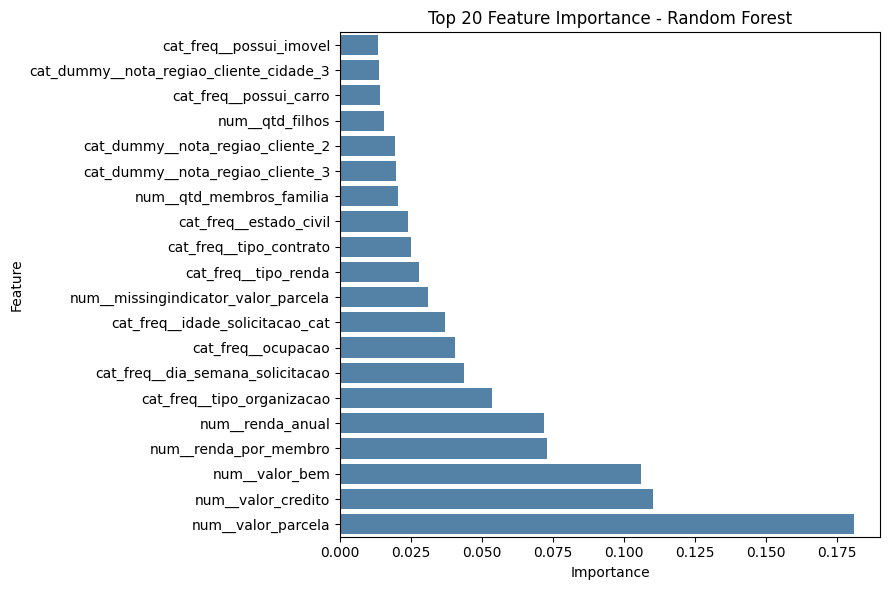

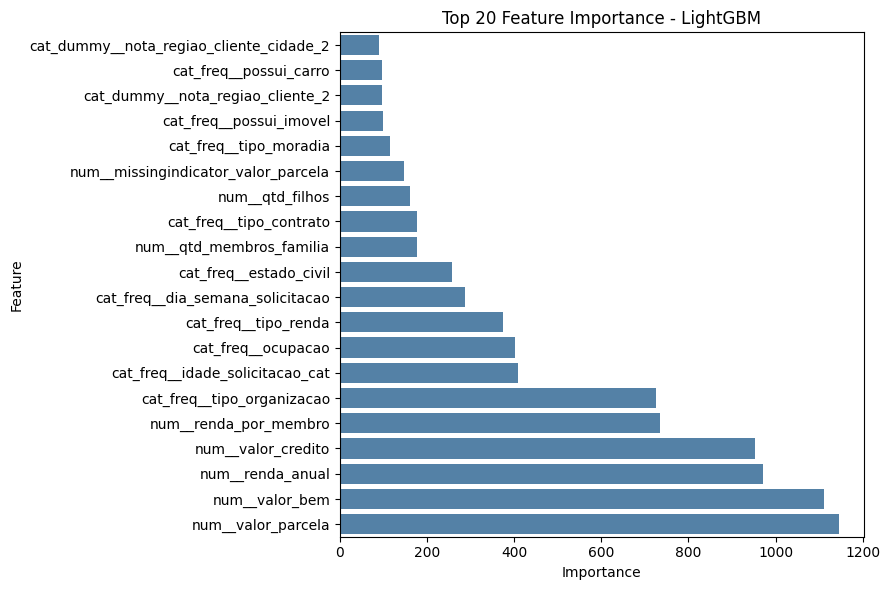

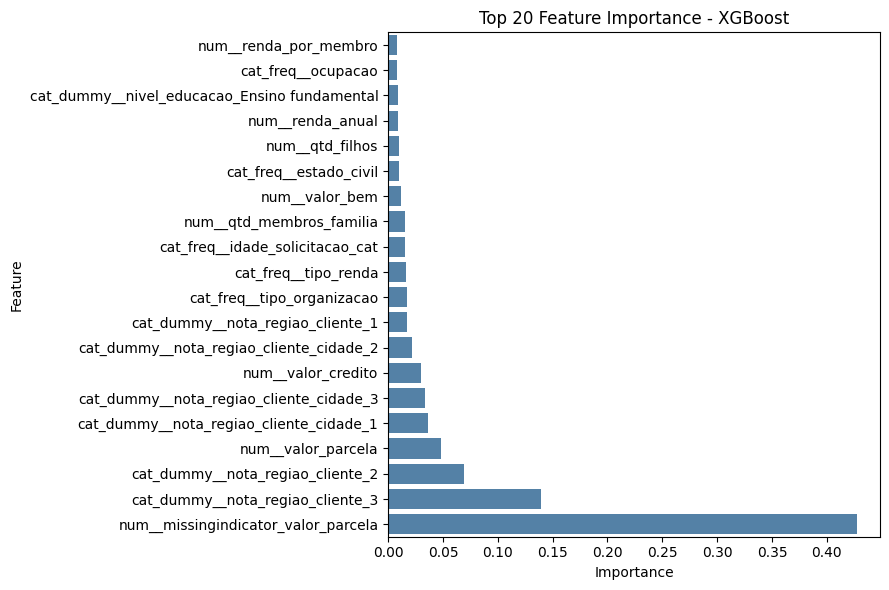

In [ ]:
def get_feature_importance(pipeline, feature_names):

    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        importance = model.feature_importances_
    elif hasattr(model, "coef_"):
        importance = np.abs(model.coef_)
    else:
        raise ValueError("Model does not provide feature importance.")
    return pd.Series(
        importance,
        index=feature_names
    ).sort_values(ascending=False)

# Plot importance for each model

for name, pipeline in fitted_models.items():
    importance = get_feature_importance(
        pipeline,
        feature_names
    ).head(20).sort_values()
    plt.figure(figsize=(9, 6))
    sns.barplot(
        x=importance.values,
        y=importance.index,
        color="steelblue"
    )

    plt.title(f"Top 20 Feature Importance - {name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


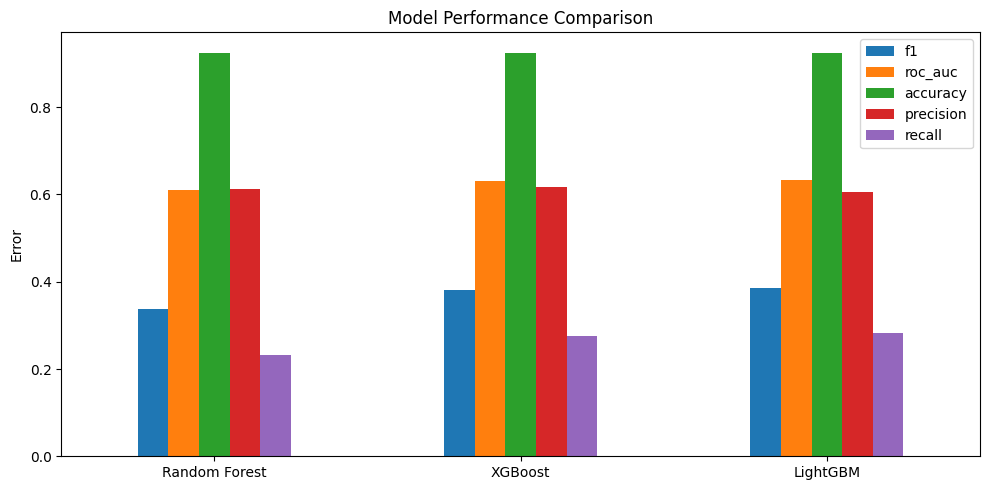

<Axes: >

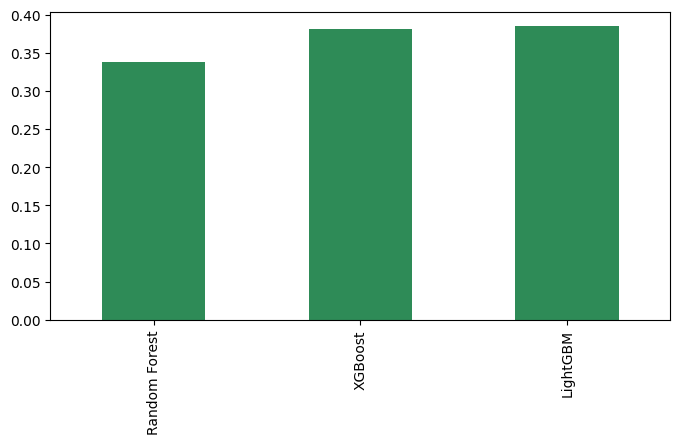

In [ ]:
# ============================================================
# 7. MODEL COMPARISON
# ============================================================

results_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df["f1"].plot(
    kind="bar",
    figsize=(8, 4),
    color="seagreen"
)

In [ ]:
import optuna

MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 10
CV_FOLDS = 5
RANDOM_STATE = 32


# ============================================================
# 2. OPTUNA OBJECTIVE
# ============================================================

def objective(trial):

    if MODEL_NAME == "randomforest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")

    # Full pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Cross-validation
    cv = KFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()


# ============================================================
# 3. OPTIMIZATION
# ============================================================

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

[I 2026-11-22 18:07:46,056] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-22 18:07:54,693] Trial 0 finished with value: -0.3600676484057333 and parameters: {'n_estimators': 200, 'learning_rate': 0.14413198475343855, 'num_leaves': 73, 'max_depth': 4, 'min_child_samples': 48, 'subsample': 0.8539565370240245, 'colsample_bytree': 0.7609844375255574, 'reg_alpha': 0.0005313513018384012, 'reg_lambda': 0.012627710308796383}. Best is trial 0 with value: -0.3600676484057333.
[I 2026-11-22 18:08:43,433] Trial 1 finished with value: -0.3813393808637427 and parameters: {'n_estimators': 900, 'learning_rate': 0.1440532196463823, 'num_leaves': 31, 'max_depth': 12, 'min_child_samples': 12, 'subsample': 0.6370143207484867, 'colsample_bytree': 0.7935821010802382, 'reg_alpha': 0.02122489197509044, 'reg_lambda': 0.026255128114845632}. Best is trial 1 with value: -0.3813393808637427.
[I 2026-11-22 18:09:16,309] Trial 2 finished with value: -0.3865509944061012 and parameters: {'n_estimators': 400, 'learning_rate': 0.04541004110132533, 'num_leaves': 54, 'max_depth': 8, '

In [ ]:
import optuna

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier


MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 3
CV_FOLDS = 5
RANDOM_STATE = 32

def objective(trial):

    if MODEL_NAME == "randomforest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")
    pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)
study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)


print("Best F1-score:", -study.best_value)
print("Best parameters:", study.best_params)


[I 2026-11-22 18:37:02,781] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/3 [00:00<?, ?it/s]

[W 2026-11-22 18:37:03,050] Trial 0 failed with parameters: {'n_estimators': 1100, 'learning_rate': 0.10295072699595681, 'num_leaves': 25, 'max_depth': 3, 'min_child_samples': 12, 'subsample': 0.6171081073800376, 'colsample_bytree': 0.933073531176205, 'reg_alpha': 4.224073602631322, 'reg_lambda': 0.02149239075877278} because of the following error: ValueError('\nAll the 5 fits failed.\nIt is very likely that your model is misconfigured.\nYou can try to debug the error by setting error_score=\'raise\'.\n\nBelow are more details about the failures:\n--------------------------------------------------------------------------------\n3 fits failed with the following error:\nTraceback (most recent call last):\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score\n    estimator.fit(X_train, y_train, **fit_params)\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper\n    return fit_

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params, raw_params=params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imbl

Best CV f1: -0.3883324652187423
Best parameters: {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145, 'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

Test performance:
f1: 0.4012055000941797


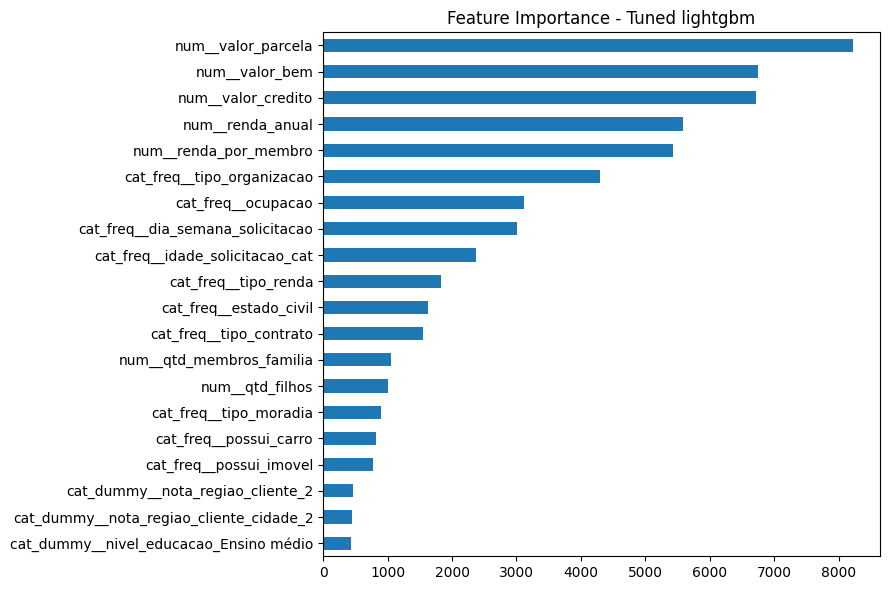

In [ ]:
print("Best CV f1:", study.best_value)
print("Best parameters:", study.best_params)


# ============================================================
# 4. FIT BEST MODEL
# ============================================================

if MODEL_NAME == "randomforest":

    best_model = RandomForestClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

elif MODEL_NAME == "lightgbm":

    best_model = LGBMClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=-1
    )


best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model)
])

best_pipeline.fit(X_train, y_train)


# ============================================================
# 5. TEST EVALUATION
# ============================================================

predictions = best_pipeline.predict(X_test)

print("\nTest performance:")
print("f1:", f1_score(y_test.fillna(False), predictions))


# ============================================================
# 6. FEATURE IMPORTANCE
# ============================================================

feature_names = (
    best_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

model = best_pipeline.named_steps["model"]

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature Importance - Tuned {MODEL_NAME}"
)

plt.tight_layout()
plt.show()

In [ ]:
def get_original_feature_name(preprocessor, transformed_name):
    transformer_name, feature_name = transformed_name.split("__", 1)
    transformers = {
        name: (transformer, columns)
        for name, transformer, columns in preprocessor.transformers_
    }
    transformer, columns = transformers[transformer_name]
    if transformer_name == "num":
        if feature_name.startswith("missingindicator_"):
            return feature_name.replace("missingindicator_", "", 1)
        return feature_name
    if transformer_name == "cat_dummy":
        encoder = transformer.named_steps["encoder"]
        encoded_names = encoder.get_feature_names_out(columns)
        for col, encoded in zip(
            [col for col in columns for _ in encoder.categories_[list(columns).index(col)]],
            encoded_names
        ):
            if encoded == feature_name:
                return col
        raise ValueError(f"Feature not found: {transformed_name}")
    if transformer_name == "cat_freq":
        return feature_name
    return feature_name
    
get_original_feature_name(pipeline['preprocessor'], 'num__valor_parcela')

'valor_parcela'

In [ ]:
n_feats = [29, 20, 15, 10, 5]
results = {}
params = {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 
          'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145,
          'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

model = LGBMClassifier(
        **params,
        random_state=32,
        verbosity=-1,
        n_jobs=-1
    )
feat_names_proc = [i for i in importance.index]

for n in n_feats:

    _feats = feat_names_proc[:n]
    _feats = list(set([get_original_feature_name(best_pipeline['preprocessor'], i) for i in _feats]))
    
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])
    cat_freq_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", FrequencyEncoder())
    ])
    cat_dummy_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder())
    ])
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, [i for i in num_features if i in _feats]),
        ("cat_freq", cat_freq_pipeline, [i for i in cat_freq_features if i in _feats]),
        ("cat_dummy", cat_dummy_pipeline, [i for i in cat_dummy_features if i in _feats])
    ])
    _pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=32,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    _pipeline.fit(X_train[_feats], y_train)
    predictions = _pipeline.predict(X_test[_feats])
    results[f'{n}_feats'] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }
    fitted_models[f'{n}_feats'] = _pipeline
    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

In [ ]:
results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)

print("\nModel performance:")
print(results_df.round(4))


Model performance:
              f1  roc_auc  accuracy  precision  recall
5_feats   0.4346   0.7203    0.8870     0.3732  0.5202
10_feats  0.4194   0.6510    0.9258     0.6043  0.3211
29_feats  0.4029   0.6416    0.9256     0.6102  0.3008
20_feats  0.4029   0.6416    0.9256     0.6102  0.3008
15_feats  0.3998   0.6390    0.9263     0.6242  0.2941


In [ ]:
feat_names_proc[:5]

['num__valor_parcela',
 'num__valor_bem',
 'num__valor_credito',
 'num__renda_anual',
 'num__renda_por_membro']